# Effect of Convex Fee Functions on Flow Control and Channel Depletion

We have seen that [selfish behavior of sending nodes and the existing linear fee function in payment channel networks such as the lighting network will put depletion preasure to channels](https://delvingbitcoin.org/t/channel-depletion-ln-topology-cycles-and-rational-behavior-of-nodes/1259) and thus decrease reliability of channels even if payments are feasible. Under the current incentives a consequence of this is that over time [the network will become less reliable and more expensive](https://x.com/renepickhardt/status/1966986717568921828). 

This is of course undesired. Note operators have for many years tried to use dynamic fees to mitigate such problems. Also Lisa Neigut has proposed [fee rate cards](https://diyhpl.us/~bryan/irc/bitcoin/bitcoin-dev/linuxfoundation-pipermail/lightning-dev/2022-September/003685.txt) which suggests to have various fee rates for a channel depending on liquidity. 

All those ideas yield of course the problem that the current gossip protocol does not support the propagation of information in real time to dynamically and quickly react to the issues. This notebook starts at [the depletion result](https://delvingbitcoin.org/t/channel-depletion-ln-topology-cycles-and-rational-behavior-of-nodes/1259) and assumes what would happen if the fee function on the protocol was not linear but convex (in our case quadratic) to begin with. 

We demonstrate that:
 * with **fixed linear fees** the network **depletes**
 * with **fixed convex fees** the network does **not deplete**.

As older proposals this new approach has the problem that a pure interpretation of the `ppm` as a convex function is not sufficient as the residual liquidity in the channel is necessary to compute the actual fee. However the notebook shows how the incentives could be improved if the protocol found a way to upgrade to convex fee functions. Note that in particular the [probabilistic part](https://arxiv.org/abs/2103.08576) of [optimally reliable payment flows is already convex](https://arxiv.org/abs/2107.05322). Making the fee function also convex would not increase the difficulty of the problem.  

**TL;DR: Turning the fee function on the lighting network to a convex fee function would mitigate channel depletion, increase reliability of payments and remove the neccassity to do dynamic fee adjustments. However sever changes to gossip with potential privacy implications may be necessary.**

I intend to publish a formal proof on those observations soon.

## Introduction

We compare two interpretations of the *same* announced fee coefficient `ppm`:

- **Linear (today’s proportional fee intuition):**  
  Define a *total fee* on an edge as $F(x)=ppm\cdot x$

  Sending **one additional sat** on an a channel will always cost you `ppm`.
  
- **Quadratic (ppm as coefficient of a quadratic total-fee):**  
  Define a *total fee* on an edge as $F(x)=ppm\cdot \frac{x^2}{CAP}$. Note that we devide the feerate by the total capacity of the channel to stay comparable with the ppm values of today's proportinal ppm interpretation.
  
  where $x$ is the cumulative net amount routed on that directed edge. (The residul that a node can still route on that edge is $CAP - x$. Thus we can interpret $x$ as a depletion proxy.)
  
  Sending an additional amount $f$ has incremental cost:

  $\Delta F = F(x+f)-F(x)=\frac{ppm}{CAP}\cdot \big(2xf + f^2\big)$
  
  For sending **1 single sat** we have: $\Delta F \approx 2\frac{ppm}{CAP}\cdot x$ (the “+1” is the small rounding term). which is proportional to the liquidity that has already been sent.

Because quadratic incremental cost grows with depletion, a cheapest-path policy will start to avoid pushing
the last sats through “overused” directions. If amounts are larger the payments will be split as utilizing too much liquidity would be too expensive.

**Important**: This approach is not gameable. For the sender it does not make a difference if it adds a large HTLC to a channel or several small HTLCs as the smaller HTLCs would become increasingly expensive. 

---

## Context / why this is interesting

- Many node operators already do **dynamic fee adjustments** based on channel balance to “signal scarcity”
  and avoid depleting outbound liquidity (this can *emulate* a convex / balance-dependent fee curve).
- Lisa Neigut proposed [fee rate cards](https://diyhpl.us/~bryan/irc/bitcoin/bitcoin-dev/linuxfoundation-pipermail/lightning-dev/2022-September/003685.txt) (tiered fee rates depending on remaining capacity), which is a
  protocol-level way to expose balance-dependent pricing without constant gossip updates.

References (starting points; see links at the end):
- René Pickhardt: *Lightning-Network-Limitations* [notebooks and posts](https://github.com/renepickhardt/Lightning-Network-Limitations/)
- Bitcoin Optech Newsletter #219: [LN fee ratecards summary](https://bitcoinops.org/en/newsletters/2022/09/28/)
- Lightning Terminal “Autofees” [documentation](https://docs.lightning.engineering/lightning-network-tools/lightning-terminal/autofees)
- Pickhardt & Richter (2021): *[Optimally Reliable & Cheap Payment Flows on the Lightning Network](https://arxiv.org/abs/2107.05322)*
- Sankagiri & Hajek (2025): *[Pricing for Routing and Flow-Control in Payment Channel Networks](https://arxiv.org/pdf/2502.20203)*

## Acknowledegments
This research is funded through [a long term support grant from OpenSats](https://opensats.org/blog/rene-pickhardt-receives-lts-grant) as well as various patreons who are supporting my research. Thanks to the folks at AMBOSS, Christian Decker and Christian Kümmerle for helpful discussions. Part of the code has been created with the help of AI models for quicker and cleaner coding (thus for example the choice to even split 1 sat payments. I kept that in because in particular in the convex setting splitting makes a lot of sense. The discrete approximation which I had in mind and explained would have been a very precice [piecewise linear approximation similar to the known one](https://github.com/renepickhardt/mpp-splitter/blob/master/Minimal%20Linearized%20min%20cost%20flow%20example%20for%20MPP.ipynb), described at [the mailinglist](https://diyhpl.us/~bryan/irc/bitcoin/bitcoin-dev/linuxfoundation-pipermail/lightning-dev/2022-March/003510.txt))

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NODES = ["A", "B", "C"]
fee_per_node = {"lin": {"A":0, "B":0, "C":0},"quad": {"A":0, "B":0, "C":0}}

# Directional fee coefficients (ppm interpreted as either linear coefficient or quadratic coefficient)
PPM = {
    ("A","B"): 1.0, ("B","A"): 1.0,
    ("A","C"): 2.0, ("C","A"): 3.0,
    ("B","C"): 2.0, ("C","B"): 1.0,  # assumed correction
}

CAP = 1000.0
INIT_BAL = CAP / 2

DIRECTED_EDGES = list(PPM.keys())

def init_balances():
    return {e: float(INIT_BAL) for e in DIRECTED_EDGES}

def other_node(s, d):
    return [x for x in NODES if x not in (s, d)][0]

def update_edge(bal, u, v, f):
    """Send f along u->v."""
    bal[(u, v)] -= f
    bal[(v, u)] += f

## Model

We simulate a triangle PCN with nodes \(A,B,C\) and 3 channels:
- $A\leftrightarrow B$
- $A\leftrightarrow C$
- $B\leftrightarrow C$

Each channel has **capacity 100 sats** and is initialized **50/50**, meaning every directed edge starts with 50 sats.

A payment of 1 sat from $u$ to $v$ routed along directed edge $(u,v)$ updates balances as:
- $\lambda(u,v)\gets \lambda(u,v)-1$
- $\lambda(v,u)\gets \lambda(v,u)+1$

So “liquidity moves” to the receiver side.

### Directional fee coefficients (ppm)
- A→B: 1,  B→A: 1  
- A→C: 2,  C→A: 3  
- B→C: 2,  C→B: 1   

### Routing / splitting (toy)

For each random 1-sat payment between distinct nodes:

- **Linear:** choose the cheapest feasible path (direct vs 2-hop), no splitting.
- **Quadratic total-fee:** allow *continuous splitting* between direct and 2-hop path, selecting the split
  that minimizes total incremental cost $\Delta F$, subject to remaining liquidity.

We have actually split the payment even though it was only a 1 sat payment. 

## Routing rules

In [5]:
def route_linear(bal, s, d, amt=1.0):
    """
    Cheapest feasible path, no splitting.
    Cost on edge (u,v): ppm(u,v) * amt.
    """
    u = other_node(s, d)

    direct_ok = bal[(s, d)] >= amt - 1e-12
    via_ok = bal[(s, u)] >= amt - 1e-12 and bal[(u, d)] >= amt - 1e-12

    if not (direct_ok or via_ok):
        return None

    direct_cost = PPM[(s, d)] * amt if direct_ok else float("inf")
    via_cost = (PPM[(s, u)] + PPM[(u, d)]) * amt if via_ok else float("inf")

    flows = {e: 0.0 for e in DIRECTED_EDGES}
    cost = 0
    if direct_cost <= via_cost:
        flows[(s, d)] = amt
        fee_per_node["lin"][s] += direct_cost 
        cost = direct_cost
    else:
        flows[(s, u)] = amt
        fee_per_node["lin"][s] += PPM[(s, u)] * amt 

        flows[(u, d)] = amt
        fee_per_node["lin"][u] += + PPM[(u, d)] * amt 

        cost = via_cost
    return flows, cost


def route_quadratic_total_fee_split(bal, s, d, amt=1.0):
    """
    Quadratic total-fee interpretation.

    On each directed edge e, define total fee F_e(x) = c_e * x^2,
    where x is cumulative 'used' amount on that directed edge.

    We approximate x by depletion: x0 = CAP - residual_liquidity.
    Sending flow f now has incremental fee:
        ΔF = c[(x0+f)^2 - x0^2] = c(2*x0*f + f^2)

    For each 1-sat payment, we allow continuous splitting:
      - direct flow x on (s,d)
      - indirect flow y=amt-x on (s,u) and (u,d)

    We choose x minimizing total incremental fees subject to liquidity constraints.
    """
    u = other_node(s, d)

    x_max = max(0.0, bal[(s, d)])                   # direct residual
    y_max = max(0.0, min(bal[(s, u)], bal[(u, d)])) # indirect bottleneck

    if x_max + y_max + 1e-12 < amt:
        return None

    # depletion states
    x0_d = CAP - bal[(s, d)]
    x0_1 = CAP - bal[(s, u)]
    x0_2 = CAP - bal[(u, d)]

    c_d = PPM[(s, d)]
    c_1 = PPM[(s, u)]
    c_2 = PPM[(u, d)]

    # Put objective into: a_d x^2 + b_d x + a_i (amt-x)^2 + b_i(amt-x)
    a_d = c_d
    b_d = 2.0 * c_d * x0_d

    a_i = c_1 + c_2
    b_i = 2.0 * (c_1 * x0_1 + c_2 * x0_2)

    # Unconstrained minimizer from derivative = 0:
    # 2(a_d+a_i)x = 2 a_i*amt + b_i - b_d
    x_star = (2.0 * a_i * amt + b_i - b_d) / (2.0 * (a_d + a_i))

    # Feasible range: x in [max(0, amt - y_max), min(amt, x_max)]
    x_low = max(0.0, amt - y_max)
    x_high = min(amt, x_max)
    x = min(max(x_star, x_low), x_high)
    y = amt - x

    flows = {e: 0.0 for e in DIRECTED_EDGES}
    cost = 0
    if x > 1e-15:
        flows[(s, d)] += x
        #\Delta F = F(x+f)-F(x)=ppm\cdot \big(2xf + f^2\big)$
        cost +=  PPM[(s,d)] * (2*(CAP-bal[(s, d)])*x + x**2)
        fee_per_node["quad"][s] += PPM[(s,d)] * (2*(CAP-bal[(s, d)])*x + x**2)/CAP 
    if y > 1e-15:
        flows[(s, u)] += y
        cost +=  PPM[(s,u)] * (2*(CAP-bal[(s, u)])*y + y**2)
        fee_per_node["quad"][s] += PPM[(s,u)] * (2*(CAP-bal[(s, u)])*y + y**2)/CAP
        flows[(u, d)] += y
        cost +=  PPM[(u,d)] * (2*(CAP-bal[(u, d)])*y + y**2)
        fee_per_node["quad"][u] += PPM[(u,d)] * (2*(CAP-bal[(u, d)])*y + y**2)/CAP
    return flows, cost/CAP

## Simulation

We run `steps` random 1-sat payments between random distinct node pairs.

You can experiment with:
- `seed` for reproducibility,
- `steps`,
- `CAP` / `INIT_BAL`,
- the fee coefficients `PPM`,
- alternative routing/splitting rules.

In [8]:
def simulate(mode="linear", steps=18000, amt=1.0, seed=21):
    random.seed(seed)
    bal = init_balances()
    rows = []
    cum_flow = {e: 0.0 for e in DIRECTED_EDGES}

    for k in range(steps):
        s, d = random.sample(NODES, 2)

        if mode == "linear":
            flows, cost = route_linear(bal, s, d, amt)
        elif mode == "quadratic":
            flows, cost = route_quadratic_total_fee_split(bal, s, d, amt)
        else:
            raise ValueError("mode must be 'linear' or 'quadratic'")

        if flows is None:
            rows.append({
                "step": k, "sender": s, "receiver": d, "success": False,
                **{f"bal_{a}{b}": bal[(a,b)] for (a,b) in DIRECTED_EDGES},
                 "cost" : cost
            })
            break

        for (u,v), f in flows.items():
            if f > 0:
                update_edge(bal, u, v, f)
                cum_flow[(u,v)] += f

        rows.append({
            "step": k, "sender": s, "receiver": d, "success": True,
            **{f"flow_{a}{b}": flows[(a,b)] for (a,b) in DIRECTED_EDGES},
            **{f"bal_{a}{b}": bal[(a,b)] for (a,b) in DIRECTED_EDGES},
            "cost" : cost
        })

    return pd.DataFrame(rows), cum_flow

fee_per_node = {"lin": {"A":0, "B":0, "C":0},"quad": {"A":0, "B":0, "C":0}}

df_lin, flow_lin = simulate("linear")
df_quad, flow_quad = simulate("quadratic")

print("linear  steps:", len(df_lin), "success rate:", df_lin["success"].mean())
print("quad    steps:", len(df_quad), "success rate:", df_quad["success"].mean())

linear  steps: 18000 success rate: 1.0
quad    steps: 18000 success rate: 1.0


### Summary helpers

In [11]:
def first_hit_zero(df, a, b, tol=1e-9):
    col = f"bal_{a}{b}"
    idx = df.index[df[col] <= tol]
    return int(df.loc[idx[0], "step"]) if len(idx) else None

def summarize(df, flows):
    mins = {f"{a}->{b}": float(df[f"bal_{a}{b}"].min()) for (a,b) in DIRECTED_EDGES}
    finals = {f"{a}->{b}": float(df.iloc[-1][f"bal_{a}{b}"]) for (a,b) in DIRECTED_EDGES}
    hit0 = {f"{a}->{b}": first_hit_zero(df, a, b) for (a,b) in DIRECTED_EDGES}
    totals = {f"{a}->{b}": float(flows[(a,b)]) for (a,b) in DIRECTED_EDGES}

    out = pd.DataFrame({
        "min_balance": pd.Series(mins),
        "final_balance": pd.Series(finals),
        "first_hit_0_step": pd.Series(hit0),
        "total_flow": pd.Series(totals),
    })
    out.index.name = "directed_edge"
    return out.sort_index()

summary_lin = summarize(df_lin, flow_lin)
summary_quad = summarize(df_quad, flow_quad)

display(summary_lin)
display(summary_quad)

,min_balance,final_balance,first_hit_0_step,total_flow
directed_edge,,,,
A->B,499.0,827.0,NaN,5584.0
A->C,0.0,0.0,2875.0,500.0
B->A,29.0,173.0,NaN,5911.0
B->C,500.0,892.0,NaN,5529.0
C->A,500.0,1000.0,NaN,0.0
C->B,31.0,108.0,NaN,5921.0


,min_balance,final_balance,first_hit_0_step,total_flow
directed_edge,,,,
A->B,464.4,492.4,None,3169.4
A->C,298.6,334.6,None,2914.6
B->A,410.8,507.6,None,3161.8
B->C,500.0,557.4,None,3114.4
C->A,500.0,665.4,None,2749.2
C->B,382.0,442.6,None,3171.8


## Visualizations

We plot each channel’s two directed balances over time for both models. We can observe that with a linear fee function one channel depletes over time. However in the convex setting the channels keep funds.

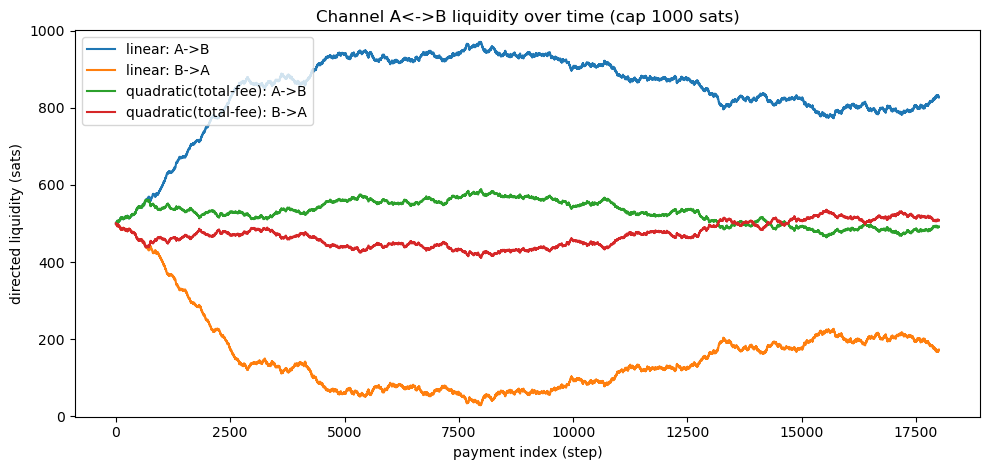

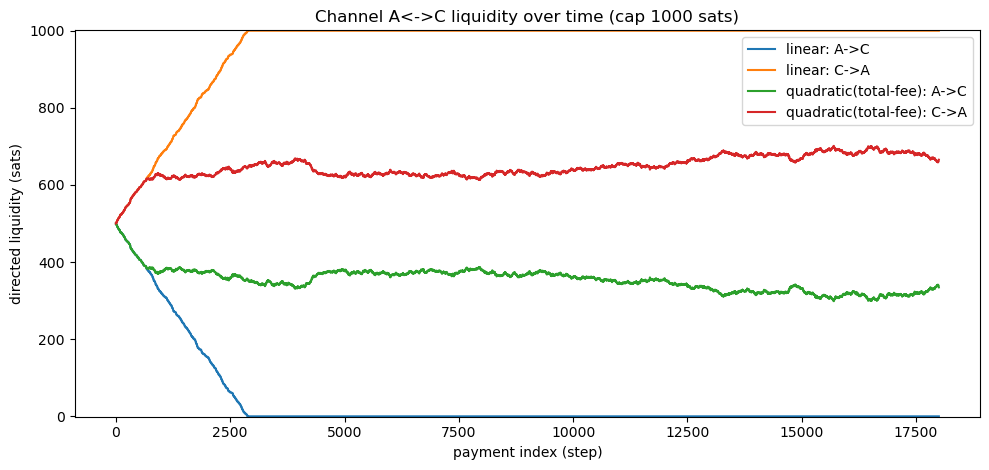

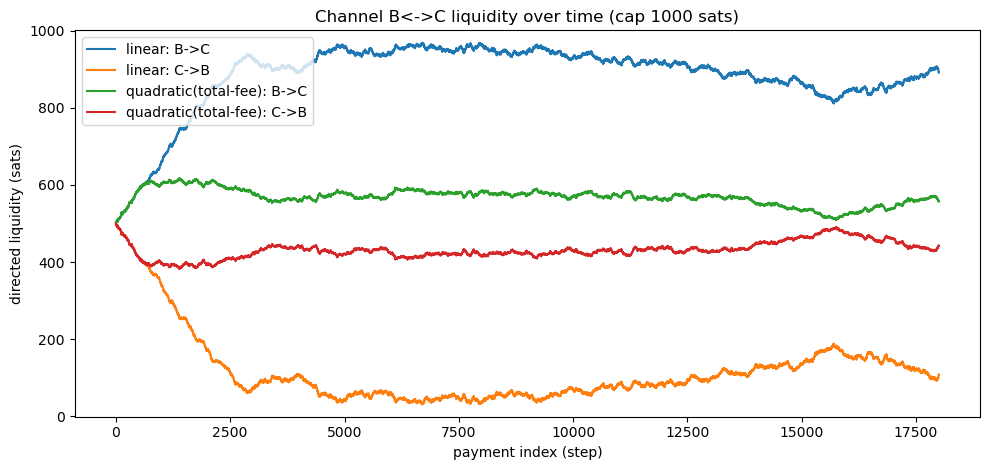

In [14]:
def plot_channel(df_a, df_b, label_a, label_b, u, v):
    plt.figure(figsize=(10, 4.8))
    x = df_a["step"]
    plt.plot(x, df_a[f"bal_{u}{v}"], label=f"{label_a}: {u}->{v}")
    plt.plot(x, df_a[f"bal_{v}{u}"], label=f"{label_a}: {v}->{u}")
    plt.plot(x, df_b[f"bal_{u}{v}"], label=f"{label_b}: {u}->{v}")
    plt.plot(x, df_b[f"bal_{v}{u}"], label=f"{label_b}: {v}->{u}")
    plt.ylim(-1, CAP+1)
    plt.xlabel("payment index (step)")
    plt.ylabel("directed liquidity (sats)")
    plt.title(f"Channel {u}<->{v} liquidity over time (cap {int(CAP)} sats)")
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_channel(df_lin, df_quad, "linear", "quadratic(total-fee)", "A", "B")
plot_channel(df_lin, df_quad, "linear", "quadratic(total-fee)", "A", "C")
plot_channel(df_lin, df_quad, "linear", "quadratic(total-fee)", "B", "C")

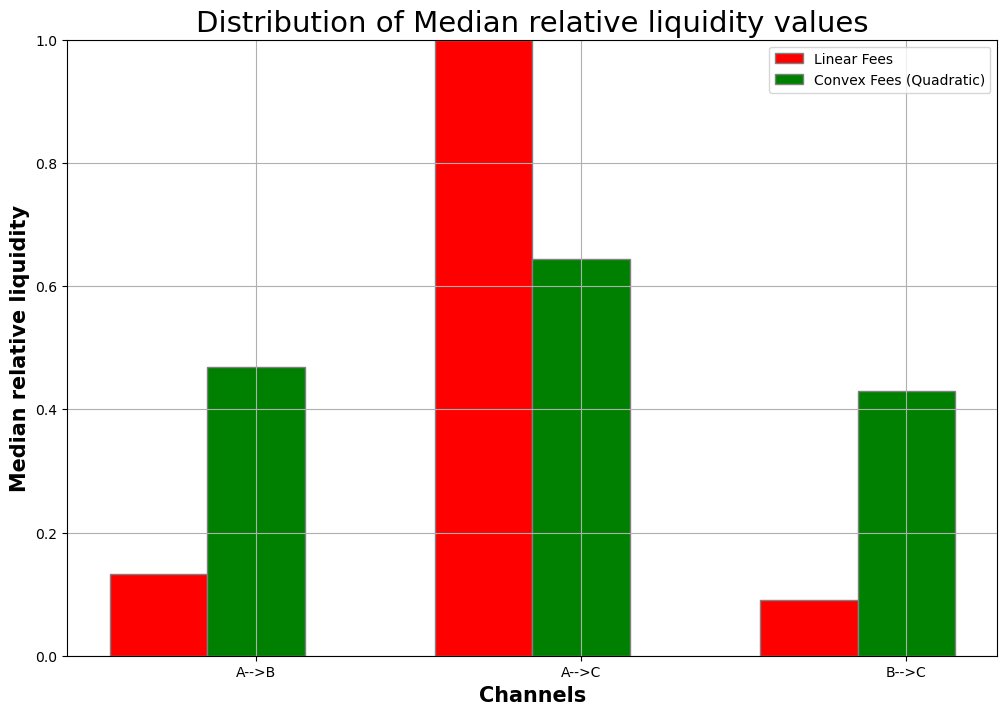

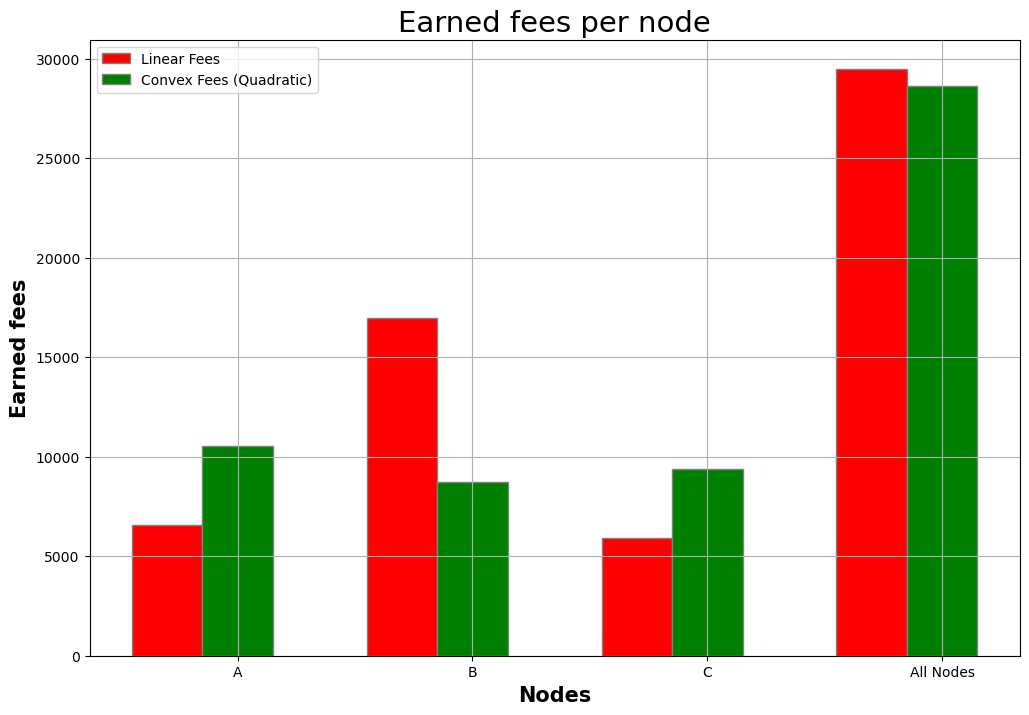

In [16]:
def plot_channel_depletion(df_a, df_b, label_a, label_b, u, v):

    barWidth = 0.3
    plt.figure(figsize =(12, 8)) 
    plt.title("Distribution of Median relative liquidity values", fontsize = 21)

    LIN = [1-np.median(df_a[f"bal_AB"])/CAP,
        1-np.median(df_a[f"bal_AC"])/CAP,
        1-np.median(df_a[f"bal_BC"])/CAP] 
    QUAD = [1-np.median(df_b[f"bal_AB"])/CAP,
        1-np.median(df_b[f"bal_AC"])/CAP,
        1-np.median(df_b[f"bal_BC"])/CAP] 

    br1 = np.arange(len(LIN)) 
    br2 = [x + barWidth for x in br1] 

    plt.bar(br1, LIN, color ='r', width = barWidth, 
        edgecolor ='grey', label ='Linear Fees') 
    plt.bar(br2, QUAD, color ='g', width = barWidth, 
        edgecolor ='grey', label ='Convex Fees (Quadratic)') 

    plt.xlabel('Channels', fontweight ='bold', fontsize = 15) 
    plt.ylabel('Median relative liquidity', fontweight ='bold', fontsize = 15) 
    plt.xticks([r + barWidth for r in range(len(LIN))], 
        ['A-->B', 'A-->C', 'B-->C'])
    plt.ylim(0,1)
    plt.grid()

    plt.legend()
    plt.show() 
    

plot_channel_depletion(df_lin, df_quad, "linear", "quadratic(total-fee)", "A", "B")


barWidth = 0.3
plt.figure(figsize =(12, 8)) 
plt.title("Earned fees per node", fontsize = 21)

fee_per_node
{'lin': {'A': 6584.0, 'B': 16969.0, 'C': 5921.0},
 'quad': {'A': 10522.69115999999,
  'B': 8710.905079999973,
  'C': 9370.991159999996}} 
LIN = [fee_per_node["lin"]["A"],fee_per_node["lin"]["B"],fee_per_node["lin"]["C"]]
LIN.append(sum(LIN))
QUAD = [fee_per_node["quad"]["A"],fee_per_node["quad"]["B"],fee_per_node["quad"]["C"]] 
QUAD.append(sum(QUAD))

br1 = np.arange(len(LIN)) 
br2 = [x + barWidth for x in br1] 

plt.bar(br1, LIN, color ='r', width = barWidth, 
    edgecolor ='grey', label ='Linear Fees') 
plt.bar(br2, QUAD, color ='g', width = barWidth, 
    edgecolor ='grey', label ='Convex Fees (Quadratic)') 

plt.xlabel('Nodes', fontweight ='bold', fontsize = 15) 
plt.ylabel('Earned fees', fontweight ='bold', fontsize = 15) 
plt.xticks([r + barWidth for r in range(len(LIN))], 
    ['A', 'B', 'C', "All Nodes"])
plt.grid()

plt.legend()
plt.show() 

### Where did the flow go?

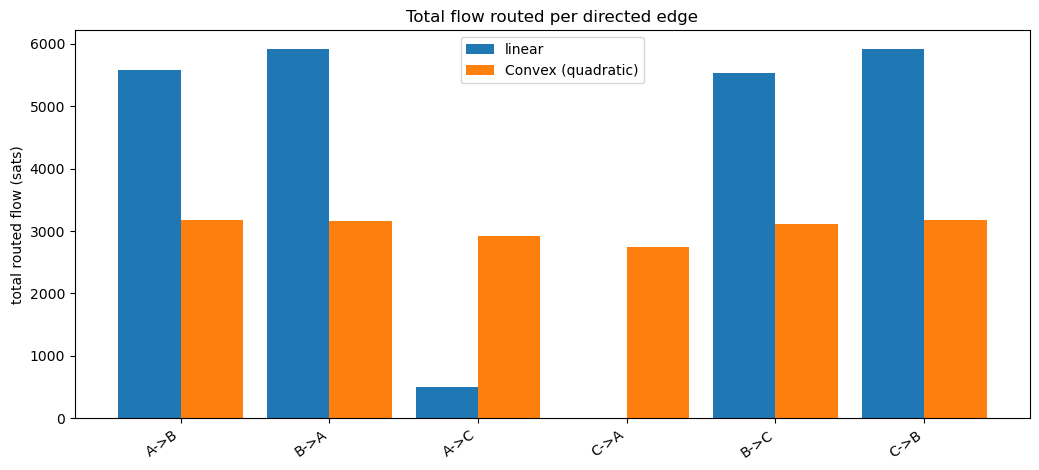

In [19]:
def plot_total_flow(flow_a, flow_b, label_a, label_b):
    edges = [f"{a}->{b}" for (a,b) in DIRECTED_EDGES]
    vals_a = [flow_a[(a,b)] for (a,b) in DIRECTED_EDGES]
    vals_b = [flow_b[(a,b)] for (a,b) in DIRECTED_EDGES]
    x = np.arange(len(edges))
    w = 0.42
    plt.figure(figsize=(10.5, 4.8))
    plt.bar(x - w/2, vals_a, width=w, label=label_a)
    plt.bar(x + w/2, vals_b, width=w, label=label_b)
    plt.xticks(x, edges, rotation=35, ha="right")
    plt.ylabel("total routed flow (sats)")
    plt.title("Total flow routed per directed edge")
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_total_flow(flow_lin, flow_quad, "linear", "Convex (quadratic)")

## Effect of one node raising fees redicolusly

here we can see what happens if a single node raises their fees redicolusly. 

IN this case A had set it's fees on both channels to 15 PPM. surprisingly A earns more (even in the liniear setting) I assume it happens when the other channels are depleted. This is however rare. in the convex case it makes sense that the entire network earns more

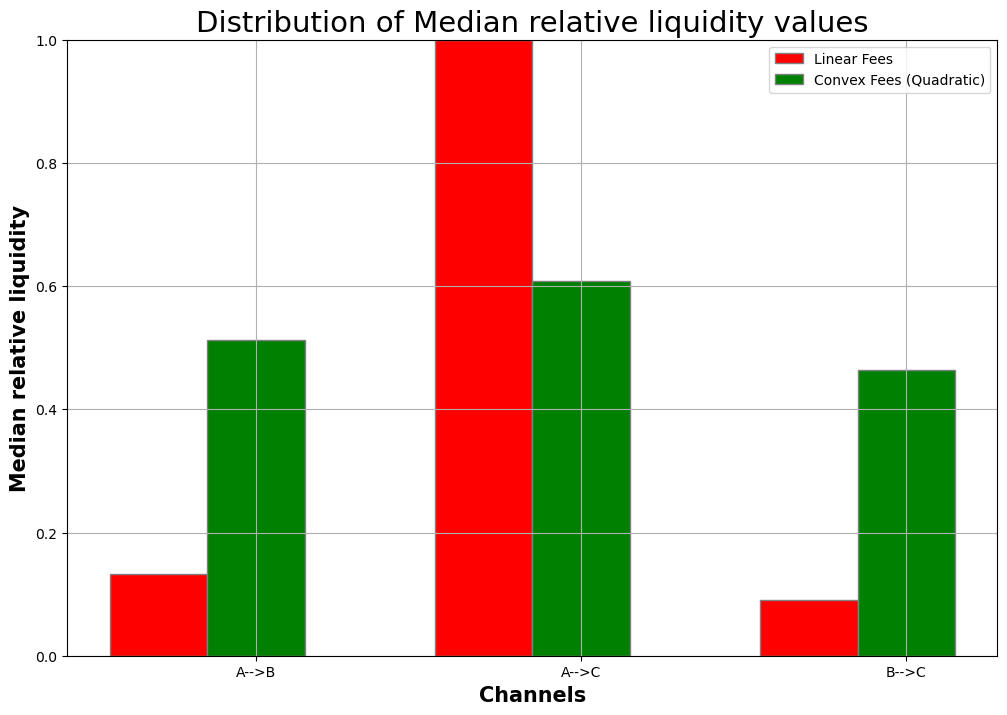

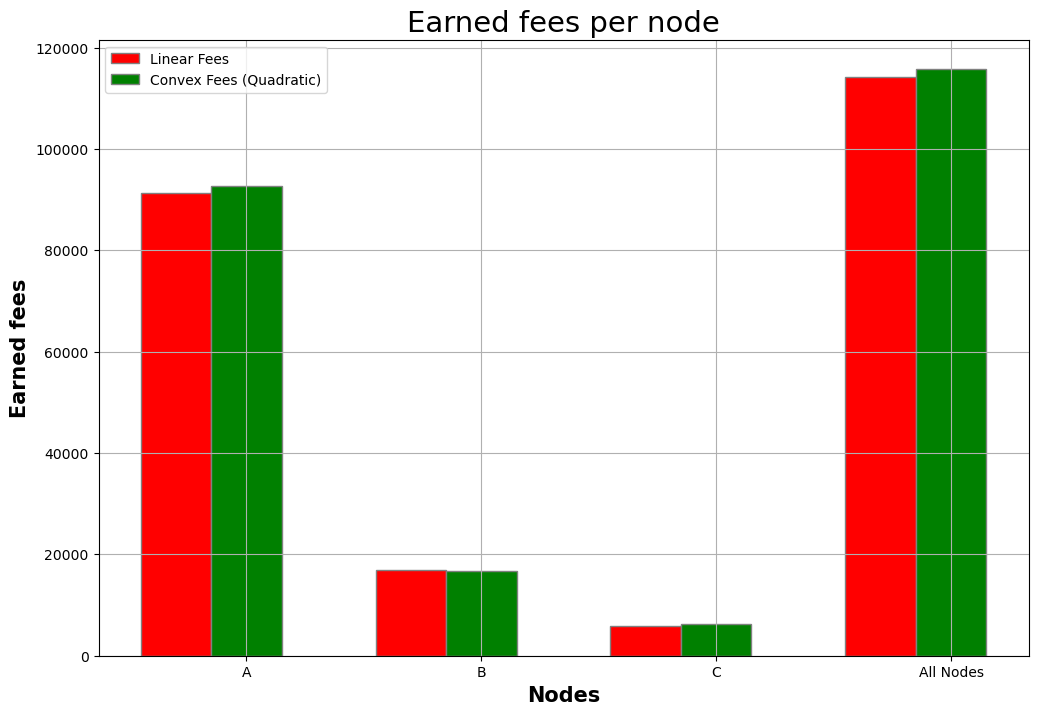

In [352]:
def plot_channel_depletion(df_a, df_b, label_a, label_b, u, v):

    barWidth = 0.3
    plt.figure(figsize =(12, 8)) 
    plt.title("Distribution of Median relative liquidity values", fontsize = 21)

    LIN = [1-np.median(df_a[f"bal_AB"])/CAP,
        1-np.median(df_a[f"bal_AC"])/CAP,
        1-np.median(df_a[f"bal_BC"])/CAP] 
    QUAD = [1-np.median(df_b[f"bal_AB"])/CAP,
        1-np.median(df_b[f"bal_AC"])/CAP,
        1-np.median(df_b[f"bal_BC"])/CAP] 

    br1 = np.arange(len(LIN)) 
    br2 = [x + barWidth for x in br1] 

    plt.bar(br1, LIN, color ='r', width = barWidth, 
        edgecolor ='grey', label ='Linear Fees') 
    plt.bar(br2, QUAD, color ='g', width = barWidth, 
        edgecolor ='grey', label ='Convex Fees (Quadratic)') 

    plt.xlabel('Channels', fontweight ='bold', fontsize = 15) 
    plt.ylabel('Median relative liquidity', fontweight ='bold', fontsize = 15) 
    plt.xticks([r + barWidth for r in range(len(LIN))], 
        ['A-->B', 'A-->C', 'B-->C'])
    plt.ylim(0,1)
    plt.grid()

    plt.legend()
    plt.show() 
    

plot_channel_depletion(df_lin, df_quad, "linear", "quadratic(total-fee)", "A", "B")


barWidth = 0.3
plt.figure(figsize =(12, 8)) 
plt.title("Earned fees per node", fontsize = 21)

fee_per_node
{'lin': {'A': 6584.0, 'B': 16969.0, 'C': 5921.0},
 'quad': {'A': 10522.69115999999,
  'B': 8710.905079999973,
  'C': 9370.991159999996}} 
LIN = [fee_per_node["lin"]["A"],fee_per_node["lin"]["B"],fee_per_node["lin"]["C"]]
LIN.append(sum(LIN))
QUAD = [fee_per_node["quad"]["A"],fee_per_node["quad"]["B"],fee_per_node["quad"]["C"]] 
QUAD.append(sum(QUAD))

br1 = np.arange(len(LIN)) 
br2 = [x + barWidth for x in br1] 

plt.bar(br1, LIN, color ='r', width = barWidth, 
    edgecolor ='grey', label ='Linear Fees') 
plt.bar(br2, QUAD, color ='g', width = barWidth, 
    edgecolor ='grey', label ='Convex Fees (Quadratic)') 

plt.xlabel('Nodes', fontweight ='bold', fontsize = 15) 
plt.ylabel('Earned fees', fontweight ='bold', fontsize = 15) 
plt.xticks([r + barWidth for r in range(len(LIN))], 
    ['A', 'B', 'C', "All Nodes"])
plt.grid()

plt.legend()
plt.show() 

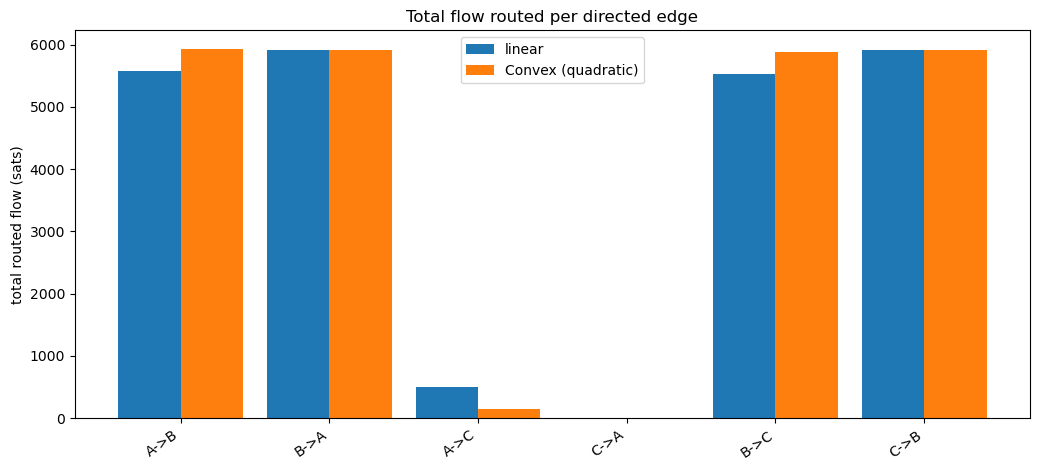

In [41]:
def plot_total_flow(flow_a, flow_b, label_a, label_b):
    edges = [f"{a}->{b}" for (a,b) in DIRECTED_EDGES]
    vals_a = [flow_a[(a,b)] for (a,b) in DIRECTED_EDGES]
    vals_b = [flow_b[(a,b)] for (a,b) in DIRECTED_EDGES]
    x = np.arange(len(edges))
    w = 0.42
    plt.figure(figsize=(10.5, 4.8))
    plt.bar(x - w/2, vals_a, width=w, label=label_a)
    plt.bar(x + w/2, vals_b, width=w, label=label_b)
    plt.xticks(x, edges, rotation=35, ha="right")
    plt.ylabel("total routed flow (sats)")
    plt.title("Total flow routed per directed edge")
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_total_flow(flow_lin, flow_quad, "linear", "Convex (quadratic)")